# Training and Test Errors, Cross-Validation, Pipelines — INSTRUCTOR SOLUTION

**How to use this notebook.** Each numbered question is followed by a written answer *and* the code that checks
it, so every claim has a number next to it. The code answers (part 10, the fix in part 11, and the competition
at the end) are in five beats: **Approach** → **code** (complete and executed) → **What the code does** →
**Expected output** → **Common mistakes**. Everything else is the student notebook, unchanged — including the
`cross_val_score` cell that is meant to fail; it is left as is, so its warning / error output is on screen.

**Links to the topic.** Topic 9.2 and the *Cross-validation in motion* section of the animation page
(`week_9/algorithms.html#cv` on the course site) show the same mechanics on eight houses: training vs
validation RMSE, K folds, a fresh model per fold, the average. This notebook does it on 2,930 houses.

Conventions below: `root_mean_squared_error` for RMSE in dollars; `scoring="neg_root_mean_squared_error"` in
`cross_val_score` (negate the scores); `cv=10` matches the student cell (10 consecutive folds); the competition
uses `KFold(10, shuffle=True, random_state=5544)` so every candidate is judged on the *same* folds.

In [1]:
import pandas as pd
import numpy as np

from plotnine import *

**Use scikit-learn, including pipelines, whenever possible.**

## Ames Housing Data


We have fit different regression models to predict house prices (SalePrice, not log). Now we will evaluate models by estimating their prediction error.

In [2]:
df_ames = pd.read_csv("http://dlsun.github.io/pods/data/AmesHousing.txt", sep = "\t")

df_ames

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,2926,923275080,80,RL,37.0,7937,Pave,NaN,IR1,Lvl,...,0,NaN,GdPrv,NaN,0,3,2006,WD,Normal,142500
2926,2927,923276100,20,RL,NaN,8885,Pave,NaN,IR1,Low,...,0,NaN,MnPrv,NaN,0,6,2006,WD,Normal,131000
2927,2928,923400125,85,RL,62.0,10441,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,Shed,700,7,2006,WD,Normal,132000
2928,2929,924100070,20,RL,77.0,10010,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2006,WD,Normal,170000


Since all of the houses in the data set have a SalePrice, we'll include all the observations in the training data. We'll start with a basic linear regression model with a few features.

In [3]:
X_train = df_ames[["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"]]

y_train = df_ames["SalePrice"]

In [4]:
from sklearn.linear_model import LinearRegression

model1 = LinearRegression()
model1.fit(
    X=X_train,
    y=y_train
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 118.1 ,-29994.96, 26728.53, 1271.14]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['Gr Liv Area','Bedroom AbvGr','Full Bath','Half Bath']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.694e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


1. Explain conceptually what the "fit" step does. What is the output?

**Answer 1.** `fit` is the **learning step**. For a linear model it is least squares: scikit-learn searches over
every combination of intercept and four slopes and keeps the one that makes the **sum of squared residuals**
(actual − predicted price, squared, added over the 2,930 houses) as small as possible. Nothing else is tried;
"fit" is this optimization.

The **output** is the fitted model object itself, `model1`, which now carries the learned **parameters**:
`model1.intercept_` and `model1.coef_` (one coefficient per feature, in dollars per unit of that feature). The
trailing underscores mark "learned from data". Those five numbers *are* the model; `predict` just evaluates
intercept + Σ coefficient × feature.

In [5]:
print("intercept:", round(model1.intercept_))
pd.Series(model1.coef_, index=X_train.columns, name="dollars per unit").round(1)

intercept: 46942


Gr Liv Area        118.1
Bedroom AbvGr   -29995.0
Full Bath        26728.5
Half Bath         1271.1
Name: dollars per unit, dtype: float64

2. Explain conceptually how you would compute the *training* RMSE (root mean square error) of this model.

**Answer 2.** The training RMSE is the typical size of the model's error *on the houses it was fitted to*:

1. predict a price for every training house: `model1.predict(X_train)`;
2. subtract from the actual prices to get 2,930 residuals (actual − predicted);
3. square them (so over- and under-predictions do not cancel), average, take the square root — back to dollars.

`root_mean_squared_error(y_train, model1.predict(X_train))` does steps 2–3 in one call. "Training" because the
same rows were used to fit *and* to score.

In [6]:
from sklearn.metrics import root_mean_squared_error

predicted = model1.predict(X_train)
residuals = y_train - predicted
by_hand = np.sqrt((residuals ** 2).mean())
print("training RMSE by hand:", round(by_hand), "   with scikit-learn:", round(root_mean_squared_error(y_train, predicted)))

training RMSE by hand: 51350    with scikit-learn: 51350


3. Interpret the *training RMSE*. Is it big or small? What could you use as a rough benchmark for comparison?

**Answer 3.** About **$51,350**: on a typical house this model misses the sale price by roughly fifty thousand
dollars. That is big — the median house sells for $160,000, so the typical error is about a third of a typical
price.

Benchmarks for "big or small":

- **Predict the mean for every house.** The dumbest model's RMSE is the standard deviation of `SalePrice`,
  about **$79,900**. Four features bring that down to 51,350 — an improvement, but only to 64 % of the
  no-information error. (Equivalently R² ≈ 0.59: the model explains 59 % of the variance.)
- **The price scale itself**: median $160,000, so a 51,000 miss is roughly ±32 %. A realtor would not accept it.
- **A better model** (the competition at the end gets below $27,000) shows how much room there was.

In [7]:
sd_price = y_train.std()
rmse_mean_model = root_mean_squared_error(y_train, np.full(len(y_train), y_train.mean()))
print(f"sd of SalePrice: {sd_price:,.0f}   RMSE of 'predict the mean': {rmse_mean_model:,.0f}")
print(f"median SalePrice: {y_train.median():,.0f}   training RMSE as a share of it: {by_hand / y_train.median():.0%}")
print(f"R^2 of model1: {model1.score(X_train, y_train):.3f}")

sd of SalePrice: 79,887   RMSE of 'predict the mean': 79,873
median SalePrice: 160,000   training RMSE as a share of it: 32%
R^2 of model1: 0.587


4. Suppose we add more features like "TotRms AbvGrd" and fit a new model. Would the *training* RMSE increase or decrease? Why is comparing the *training* RMSE of these two models not useful?

**Answer 4.** The training RMSE can only **decrease (or stay the same), never increase.** Least squares with
the extra column can always set that column's coefficient to 0 and recover the old model exactly, so the best
fit with five features is at least as good as the best fit with four. Here the drop is almost nothing —
`TotRms AbvGrd` is nearly redundant with bedrooms, baths and living area — but the sign is guaranteed.

That is exactly why comparing *training* RMSEs is **not useful**: the more complex model wins (or ties) by
construction, whether or not it predicts new houses any better. The comparison is rigged in favour of
complexity. We need an error measured on houses the model has *not* seen — parts 7–10.

In [8]:
features5 = ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath", "TotRms AbvGrd"]
model_5 = LinearRegression().fit(df_ames[features5], y_train)
rmse4 = root_mean_squared_error(y_train, model1.predict(X_train))
rmse5 = root_mean_squared_error(y_train, model_5.predict(df_ames[features5]))
print(f"training RMSE, 4 features: {rmse4:,.2f}")
print(f"training RMSE, 5 features: {rmse5:,.2f}   (decrease of {rmse4 - rmse5:,.2f} dollars)")

training RMSE, 4 features: 51,350.42
training RMSE, 5 features: 51,350.40   (decrease of 0.02 dollars)


5. If we fit a 1-nearest neighbor model, what should the *training* RMSE be?

**Answer 5.** It *should* be **0**. Each training house's nearest neighbor is itself (distance 0), so 1-NN
"predicts" its own price exactly. Training error zero is the signature of a model that has memorized the data
— and says nothing about how it would do on a new house.

The fine print, which this data set happens to exhibit: 1,197 houses share an **identical feature row** (same
living area, bedrooms, full and half baths) with at least one other house that sold for a *different* price.
For those, several houses tie at distance 0, scikit-learn picks one of them, and the "prediction" can be the
twin's price. So 1-NN's training RMSE on these four features is not 0 but about **$21,700** (21,900 with the
features scaled, since scaling changes which twin wins a tie) — still far below any other model's, and exactly
0 as soon as the tied rows are removed (second cell).

In [9]:
from sklearn.neighbors import KNeighborsRegressor

knn1 = KNeighborsRegressor(n_neighbors=1).fit(X_train, y_train)
print("1-NN training RMSE on all 2,930 houses:", round(root_mean_squared_error(y_train, knn1.predict(X_train))))
print("houses whose four features are identical to another house's:", X_train.duplicated(keep=False).sum())

1-NN training RMSE on all 2,930 houses: 21659
houses whose four features are identical to another house's: 1197


In [10]:
unique_rows = ~X_train.duplicated(keep=False)                 # houses with a one-of-a-kind feature row
knn1u = KNeighborsRegressor(n_neighbors=1).fit(X_train[unique_rows], y_train[unique_rows])
print("1-NN training RMSE with the tied rows removed:",
      round(root_mean_squared_error(y_train[unique_rows], knn1u.predict(X_train[unique_rows]))))

1-NN training RMSE with the tied rows removed: 0


6. What happens to the *training* RMSE of a $k$-nearest neighbors model as $k$ increases?

**Answer 6.** It **increases** as k grows. With k = 1 each training house is predicted by itself; with larger k
the prediction is the average of k houses, which pulls it away from the house's own price toward its
neighbors'. The regression function gets smoother and less flexible, so it matches the training prices less
well. At k = 2,930 (every house is a neighbor of every other) the prediction is the overall mean for everyone
and the training RMSE equals the standard deviation of price, about $79,900 — the "predict the mean" benchmark
from part 3.

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

rows = []
for k in [1, 2, 5, 20, 100, 500, len(X_train)]:
    knn = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k)).fit(X_train, y_train)
    rows.append({"k": k, "training RMSE": root_mean_squared_error(y_train, knn.predict(X_train))})
pd.DataFrame(rows).set_index("k").round(0)

,training RMSE
k,
1,21864.0
2,30800.0
5,39619.0
20,43892.0
100,48989.0
500,59367.0
2930,79873.0


7. We are really interested in the *test* RMSE, not the *training* RMSE. Explain why in practice you can not compute the *test* RMSE.

**Answer 7.** The test RMSE is the error on the houses the model will actually be used for: houses that have
**not sold yet**, or whose prices we do not know. For those, there is no `SalePrice` to compare the prediction
with, so the error cannot be computed. And every house whose price we *do* know is already in the training
data — scoring the model on them gives the training RMSE, which part 4 showed is rigged. The test error is the
number we want and the one number we can never calculate directly; the best we can do is **estimate** it,
which is what cross-validation is for.

8. Explain conceptually how cross-validations *estimates* the *test* RMSE.

**Answer 8.** Cross-validation manufactures "unseen" houses out of the training data:

1. **Cut** the training rows into K folds (K = 10 below: ten groups of 293 houses).
2. For fold 1: **hold it out**, fit a *fresh* copy of the model on the other nine folds, predict the 293 held-out
   houses, and compute the RMSE of those predictions. The model never saw their prices, so this is a genuine
   out-of-sample error.
3. **Repeat** for folds 2 … 10. Every house is held out exactly once and is predicted by a model that was not
   fitted on it.
4. **Average** the ten RMSEs. The average estimates the test RMSE; the spread of the ten shows how uncertain the
   estimate is.

Why it estimates the *test* error: each fold's model is fitted on about 90 % of the data, almost as much as the
final model, and is scored only on houses it did not train on — the same situation the final model will face
with new houses. (K is the number of folds; it has nothing to do with the k of k-nearest neighbors.)

9. We'll use cross-validation to estimate the *test* RMSE for the model from part 1. Will the *test* RMSE be greater than, less than, or equal to the *training* RMSE for this model?

**Answer 9.** **Greater than**, almost always: a model is scored on houses it did not fit, so it does a little
worse than on the ones it did. For *this* model the gap is tiny — training RMSE 51,350, 10-fold estimate of
test RMSE about **51,450** — because a line with five parameters cannot memorize 2,930 houses; it is too simple
to overfit. (A 1-NN model would show a huge gap: 21,900 vs about 60,000.)

`cross_val_score` returns one score per fold, **negative** because scikit-learn maximizes scores; negate and
average. With `scoring="neg_mean_squared_error"` as in the pre-class reading, take `np.sqrt(-scores)` fold by
fold before averaging — it gives the same number.

In [12]:
from sklearn.model_selection import cross_val_score

def cv_rmse(model, X, cv=10):
    """Cross-validation estimate of the test RMSE: mean of the per-fold RMSEs."""
    scores = cross_val_score(model, X, y_train, cv=cv, scoring="neg_root_mean_squared_error")
    return -scores.mean()

scores = cross_val_score(LinearRegression(), X_train, y_train, cv=10, scoring="neg_root_mean_squared_error")
print("per-fold validation RMSE:", (-scores).round(0))
print(f"estimated test RMSE (mean of the 10): {-scores.mean():,.0f}    training RMSE: {rmse4:,.0f}")

per-fold validation RMSE: [49190. 61053. 45199. 53745. 44186. 65626. 47843. 61320. 46254. 40138.]
estimated test RMSE (mean of the 10): 51,455    training RMSE: 51,350


In [13]:
# the reading's route: negative MSE per fold, square-root each, then average -> the same estimate
mse_scores = cross_val_score(LinearRegression(), X_train, y_train, cv=10, scoring="neg_mean_squared_error")
print("via neg_mean_squared_error:", round(np.sqrt(-mse_scores).mean()))

via neg_mean_squared_error: 51455


10. Suppose we add features like we did in part 4. Will the *test* RMSE necessarily decrease? Fit the test RMSE and compare the two models - which is better based on this criteria?

**Answer 10.** **Not necessarily.** Adding a feature is guaranteed to lower the *training* RMSE (part 4) but
can leave the *test* RMSE unchanged or make it worse: a column that carries no new information adds a
coefficient that is fitted to noise, and the noise does not repeat on new houses.

### The comparison

**Approach.** Same `cv_rmse` helper, same `cv=10`, two feature lists.

In [14]:
cv4 = cv_rmse(LinearRegression(), X_train)
cv5 = cv_rmse(LinearRegression(), df_ames[features5])
print(f"estimated test RMSE, 4 features: {cv4:,.0f}")
print(f"estimated test RMSE, 5 features: {cv5:,.0f}   (change: {cv5 - cv4:+,.0f})")

estimated test RMSE, 4 features: 51,455
estimated test RMSE, 5 features: 51,575   (change: +120)


**What the code does.** `cross_val_score` refits `LinearRegression()` ten times for each feature set and scores
each fit on its held-out fold; `cv_rmse` averages the ten RMSEs.

**Expected output.** 4 features ≈ **51,450**; 5 features ≈ **51,580**: the model *with* `TotRms AbvGrd` is
slightly **worse** on held-out houses even though its training RMSE was (microscopically) better. By this
criterion the four-feature model is the better one — and the honest conclusion is that total rooms adds nothing
once bedrooms, baths and living area are known. (The difference is small relative to the fold-to-fold spread,
so "no better" is the safest wording.)

**Common mistakes.** Comparing training RMSEs and declaring the bigger model the winner; using different folds
for the two models (set `cv` the same way for both); reporting the negative scores without flipping the sign.

11. Now suppose we add a categorical predictor like Neighborhood. The crossval code below will (probably) error. Explain why. Hint: think about how the cross-validation process works and how categorical variables are treated.

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor

ct = ColumnTransformer(
    [("standardize", StandardScaler(), ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"],),
     ("dummify", OneHotEncoder(), ["Neighborhood"]),
    ],
    remainder="drop",
)

neighborhood_model = Pipeline(
    [("preprocessing", ct),
     ("lm", LinearRegression())]
)

X_train = df_ames[["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath", "Neighborhood"]]
y_train = df_ames["SalePrice"]

neighborhood_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('lm', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['Gr Liv Area','Bedroom AbvGr','Full Bath','Half Bath','Neighborhood']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('standardize', ...), ('dummify', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of 

**Answer 11 (why the cell fails).** Two layers.

1. **The immediate error**: `cross_val_score` was never imported in the student notebook, so Python raises
   `NameError`. (In this solution notebook it *was* imported in part 9, so the cell runs — and exposes the
   second, more interesting problem.)
2. **The real problem.** Cross-validation refits the *whole pipeline* — `OneHotEncoder` included — on each
   fold's nine training folds, then transforms the held-out fold. `Neighborhood` has rare values: **Landmrk**
   has one house, **GrnHill** two, **Greens** eight. In fold 10 the single Landmrk house is in the held-out
   fold, so the encoder fitted on the other nine folds has never seen "Landmrk" and refuses to transform it:
   `ValueError: Found unknown categories ['Landmrk']`. Current scikit-learn catches that during scoring,
   issues a warning, and records **`nan`** for the fold (the last score above); older versions raised the error
   outright — hence "will (probably) error".

Why categorical variables are special here: a numeric column always *can* be transformed; a one-hot encoder
can only transform categories it was fitted on, and with few houses in a category there is a real chance that
all of them land in the validation fold.

### The fix

**Approach.** Tell the encoder what to do with a category it has not seen: `handle_unknown="ignore"` produces
an all-zero dummy row for it (the house is treated as "none of the known neighborhoods"). Shuffling the folds
also makes the problem *less* likely but does not rule it out, so the encoder setting is the real fix.

In [16]:
ct_fixed = ColumnTransformer(
    [("standardize", StandardScaler(), ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"]),
     ("dummify", OneHotEncoder(handle_unknown="ignore"), ["Neighborhood"])],
    remainder="drop",
)
neighborhood_model_fixed = Pipeline([("preprocessing", ct_fixed), ("lm", LinearRegression())])

scores = cross_val_score(neighborhood_model_fixed, X=X_train, y=y_train,
                         scoring="neg_root_mean_squared_error", cv=10)
print("per-fold validation RMSE:", (-scores).round(0))
print(f"estimated test RMSE with Neighborhood: {-scores.mean():,.0f}   (without it, part 9: {cv4:,.0f})")

per-fold validation RMSE: [38019. 46647. 32243. 41873. 33085. 49613. 37680. 48174. 34876. 32167.]
estimated test RMSE with Neighborhood: 39,438   (without it, part 9: 51,455)


**What the code does.** Same pipeline, one argument added to the encoder; `cross_val_score` now completes all
ten folds and the Landmrk house in fold 10 is encoded as all zeros.

**Expected output.** Ten numbers, no `nan`; estimated test RMSE about **39,400**, down from 51,450 — the
neighborhood is worth about twelve thousand dollars of RMSE. (The fold with the one Landmrk house predicts it
as a "no-neighborhood" house, which is a little wrong for one house and irrelevant for the average.)

**Common mistakes.** Dropping the rare neighborhoods from the data instead of handling them (the final model
must cope with them too); fitting the encoder on *all* the data first and then cross-validating — it hides
the error but leaks the validation rows' categories into training (part 12); forgetting that `X_train` was
redefined above to include `Neighborhood`.

In [17]:
scores = cross_val_score(neighborhood_model,
                         X = X_train,
                         y = y_train,
                         scoring="neg_mean_squared_error",
                         cv=10)
scores

/opt/anaconda3/lib/python3.14/site-packages/sklearn/model_selection/_validation.py:974: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.14/site-packages/sklearn/metrics/_scorer.py", line 167, in __call__
    score = scorer._score(
        cached_call, estimator, *args, **routed_params.get(name).score
    )
  File "/opt/anaconda3/lib/python3.14/site-packages/sklearn/metrics/_scorer.py", line 455, in _score
    y_pred = method_caller(
        estimator,
    ...<2 lines>...
        pos_label=pos_label,
    )
  File "/opt/anaconda3/lib/python3.14/site-packages/sklearn/metrics/_scorer.py", line 97, in _cached_call
    result, _ = _get_response_values(
                ~~~~~~~~~~~~~~~~~~~~^
        estimator, *args, response_method=response_method, **kwargs
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/opt/anaco

array([-1.44545960e+09, -2.17595046e+09, -1.03959067e+09, -1.75337711e+09,
       -1.09461091e+09, -2.46145139e+09, -1.41979799e+09, -2.32075542e+09,
       -1.21633488e+09,             nan])

11. Going back to part 1, suppose we had standardized the features first. Would the coeffiecients of the fitted model change? Would the *training* RMSE change?

**Answer 11 (standardizing first).** The **coefficients change, the training RMSE does not.**

Standardizing replaces each feature x by (x − mean) / sd. A linear model absorbs that perfectly: the new
coefficient for a feature is the old coefficient × that feature's standard deviation (so it now reads "dollars
per *standard deviation* of living area" instead of "dollars per square foot"), and the intercept becomes the
mean price, because every standardized feature is 0 at the average house. The fitted *predictions* are
identical to the dollar, so the residuals and the training RMSE are unchanged.

Standardizing matters for KNN (distances), not for least squares (coefficients adjust) — Topic 9.1's table.
It can still be useful with linear regression for comparing the sizes of coefficients across features.

In [18]:
X4 = df_ames[["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"]]
std_model = make_pipeline(StandardScaler(), LinearRegression()).fit(X4, y_train)

compare = pd.DataFrame({
    "coefficient (raw)":          model1.coef_,
    "coefficient (standardized)": std_model[-1].coef_,
    "raw coef x feature sd":      model1.coef_ * X4.std(ddof=0),
}, index=X4.columns).round(0)
print("intercept raw:", round(model1.intercept_), "  standardized:", round(std_model[-1].intercept_), "  mean price:", round(y_train.mean()))
print("largest difference between the two models' predictions:", np.abs(std_model.predict(X4) - model1.predict(X4)).max().round(6))
print("training RMSE standardized:", round(root_mean_squared_error(y_train, std_model.predict(X4))))
compare

intercept raw: 46942   standardized: 180796   mean price: 180796
largest difference between the two models' predictions: 0.0
training RMSE standardized: 51350


,coefficient (raw),coefficient (standardized),raw coef x feature sd
Gr Liv Area,118.0,59690.0,59690.0
Bedroom AbvGr,-29995.0,-24824.0,-24824.0
Full Bath,26729.0,14777.0,14777.0
Half Bath,1271.0,639.0,639.0


12. Suppose we want to standardize predictors like in the previous part and estimate test RMSE using cross-validation. Explain how standardization fits in in the CV process. Also explain why it is important to put standardization as part of the model pipeline.

**Answer 12.** Standardization is a **fitted step**: `StandardScaler` learns a mean and a standard deviation
from whatever rows it is given. Inside cross-validation it must therefore be treated like the model:

- in each fold, the scaler is **fitted on the nine training folds only**, and the held-out fold is transformed
  with *those* means and standard deviations — exactly what will happen later when a new house arrives and is
  scaled with the training statistics;
- it is refitted for every fold, because every fold has a different training set.

Putting the scaler **in the pipeline** makes `cross_val_score` do this automatically: it clones and fits the
whole pipeline on each training fold. Scaling the full data set *before* cross-validating breaks the rule in
two ways: the validation rows' values leak into the means and standard deviations the training rows are scaled
with (a small data leak that makes the estimate optimistic), and the step is no longer part of the model, so it
is easy to forget — or to apply with the wrong statistics — when predicting new houses. The pipeline also
guarantees that `predict` on new data uses the *training* scaling.

For linear regression the leak cannot move the number at all (part 11: predictions do not depend on the
scaling); for KNN, where distances depend on the scale, it is real but tiny here — a few tens of dollars with
2,930 houses, because each fold's mean and standard deviation barely differ from the full data's. The check
below does both versions for a 10-nearest-neighbor model. The principle, not the size, is the lesson.

In [19]:
from sklearn.model_selection import KFold

knn10 = KNeighborsRegressor(n_neighbors=10)
cv = KFold(n_splits=10, shuffle=True, random_state=5544)

# WRONG: scale everything first, then cross-validate (validation rows shaped the scaler)
X4_scaled = pd.DataFrame(StandardScaler().fit_transform(X4), columns=X4.columns, index=X4.index)
leaky = cv_rmse(knn10, X4_scaled, cv=cv)

# RIGHT: the scaler inside the pipeline is refitted on the training folds of every split
clean = cv_rmse(make_pipeline(StandardScaler(), knn10), X4, cv=cv)

print(f"scale first, then cross-validate: {leaky:,.0f}")
print(f"scaler inside the pipeline:       {clean:,.0f}")

scale first, then cross-validate: 46,133
scaler inside the pipeline:       46,106


## Practice Activity

We'll continue with the housing data and our goal of predicting Sale Price.

We will have a competition to see who can come up with the model with the smallest *test* RMSE. Fit several models and try to find the smallest *test* RMSE. Use cross-validation to estimate the *test* RMSE. When you think you have a good model, share your it and its test RMSE with a partner. Then see what other people have done; can you do even better?

Note: next week we will see how to make some of these choices in a more automated way. For now just work by trial and error. You should try:

- Exploring the data first! Make some plots and summaries to get an idea of what might be good predictors to try
- Several different sets of predictors, including both categorical and numerical predictors
- Linear regression models, including models with polynomial features and interactions
- K-nearest neighbors models, inclduing different values of k
- Decision trees, including different sizes of trees

Use pipelines as much as possible, and don't forget to transform variables as needed.

### Solution — the competition

**Approach.** Judge every candidate the same way: 10-fold cross-validation with **the same shuffled folds**
(`KFold(10, shuffle=True, random_state=5544)`) and RMSE in dollars, through one helper that takes a pipeline
and a list of columns. Preprocessing lives in a `ColumnTransformer`: numeric columns go through a median
imputer (two columns have a single missing value), optional `PolynomialFeatures`, and a scaler when the model
needs one; categorical columns go through `OneHotEncoder(handle_unknown="ignore")` (part 11). Then explore,
try families — linear with more features, with categoricals, with squares and interactions; KNN over k; trees
over depth — and keep a leaderboard. Nothing is tuned automatically; that is next week.

In [20]:
from sklearn.model_selection import KFold
from sklearn.preprocessing import PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeRegressor

folds = KFold(n_splits=10, shuffle=True, random_state=5544)
leaderboard = {}

def judge(name, model, columns):
    """Cross-validated RMSE (same 10 folds for every candidate), recorded on the leaderboard."""
    rmse = -cross_val_score(model, df_ames[columns], y_train, cv=folds, scoring="neg_root_mean_squared_error").mean()
    leaderboard[name] = rmse
    print(f"{name:48s} {rmse:>9,.0f}")
    return rmse

def preprocessing(numeric, categorical=(), scale=True, degree=None):
    """Impute (median) -> optional polynomial terms -> optional scaling for numerics; one-hot for categoricals."""
    steps = [("impute", SimpleImputer(strategy="median"))]
    if degree:
        steps.append(("poly", PolynomialFeatures(degree=degree, include_bias=False)))
    if scale:
        steps.append(("scale", StandardScaler()))
    transformers = [("num", Pipeline(steps), list(numeric))]
    if categorical:
        transformers.append(("cat", OneHotEncoder(handle_unknown="ignore"), list(categorical)))
    return ColumnTransformer(transformers)

**Explore first.** Which numeric columns move with price, and which categorical columns separate it?

In [21]:
numeric_candidates = ["Overall Qual", "Gr Liv Area", "Garage Cars", "Garage Area", "Total Bsmt SF", "1st Flr SF",
                      "Year Built", "Full Bath", "Year Remod/Add", "TotRms AbvGrd", "Fireplaces", "Half Bath",
                      "Lot Area", "Bedroom AbvGr", "Overall Cond", "Yr Sold"]
corr = df_ames[numeric_candidates + ["SalePrice"]].corr()["SalePrice"].drop("SalePrice").sort_values(ascending=False)
print("missing values:", df_ames[numeric_candidates].isna().sum()[lambda s: s > 0].to_dict())
corr.round(2).to_frame("correlation with SalePrice")

missing values: {'Garage Cars': 1, 'Garage Area': 1, 'Total Bsmt SF': 1}


,correlation with SalePrice
Overall Qual,0.80
Gr Liv Area,0.71
Garage Cars,0.65
Garage Area,0.64
Total Bsmt SF,0.63
1st Flr SF,0.62
Year Built,0.56
Full Bath,0.55
Year Remod/Add,0.53
TotRms AbvGrd,0.50


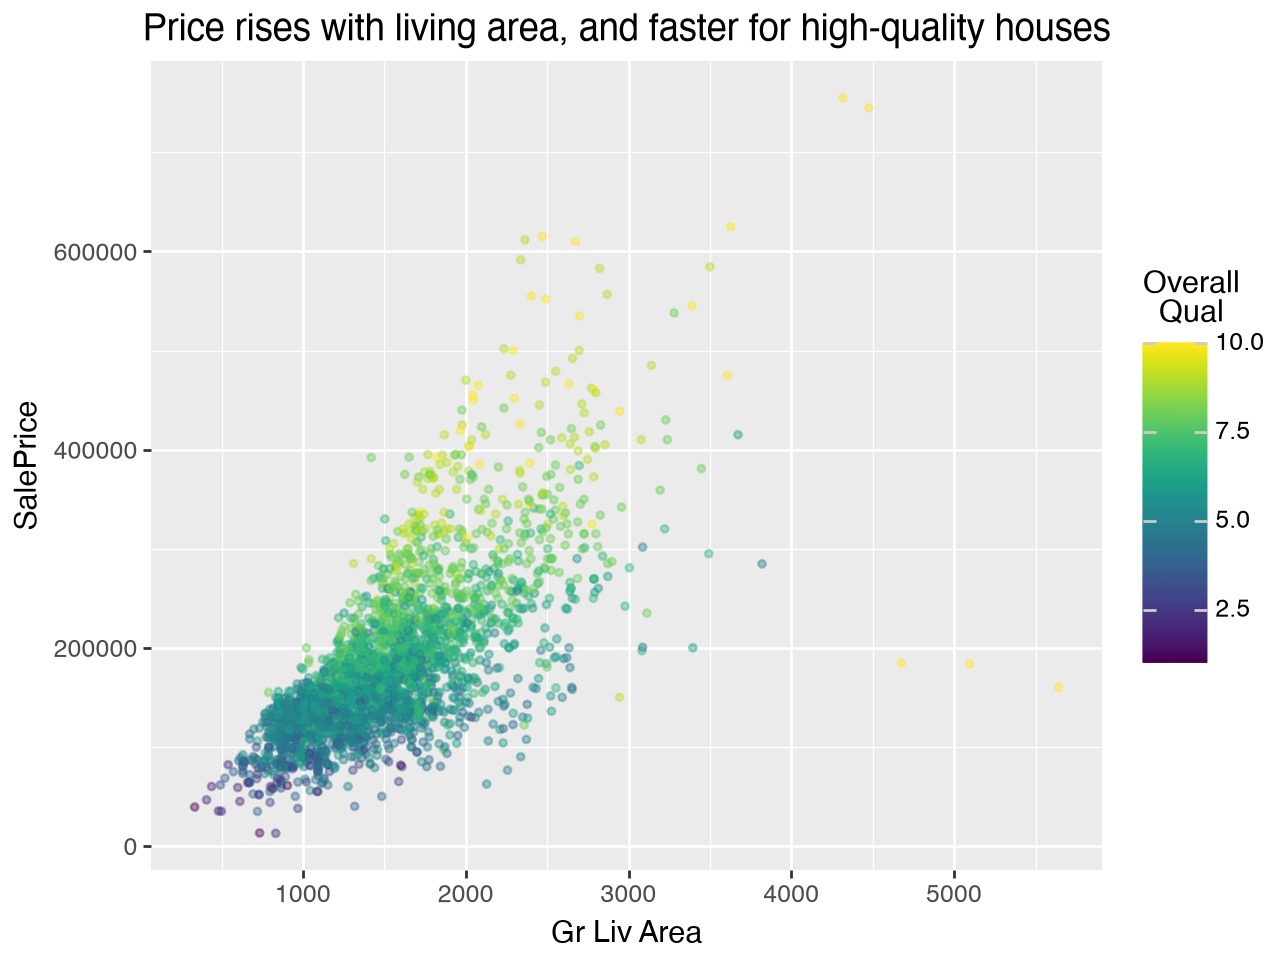

In [22]:
(ggplot(df_ames, aes(x="Gr Liv Area", y="SalePrice", color="Overall Qual"))
 + geom_point(alpha=0.4, size=1)
 + labs(title="Price rises with living area, and faster for high-quality houses", color="Overall\nQual"))

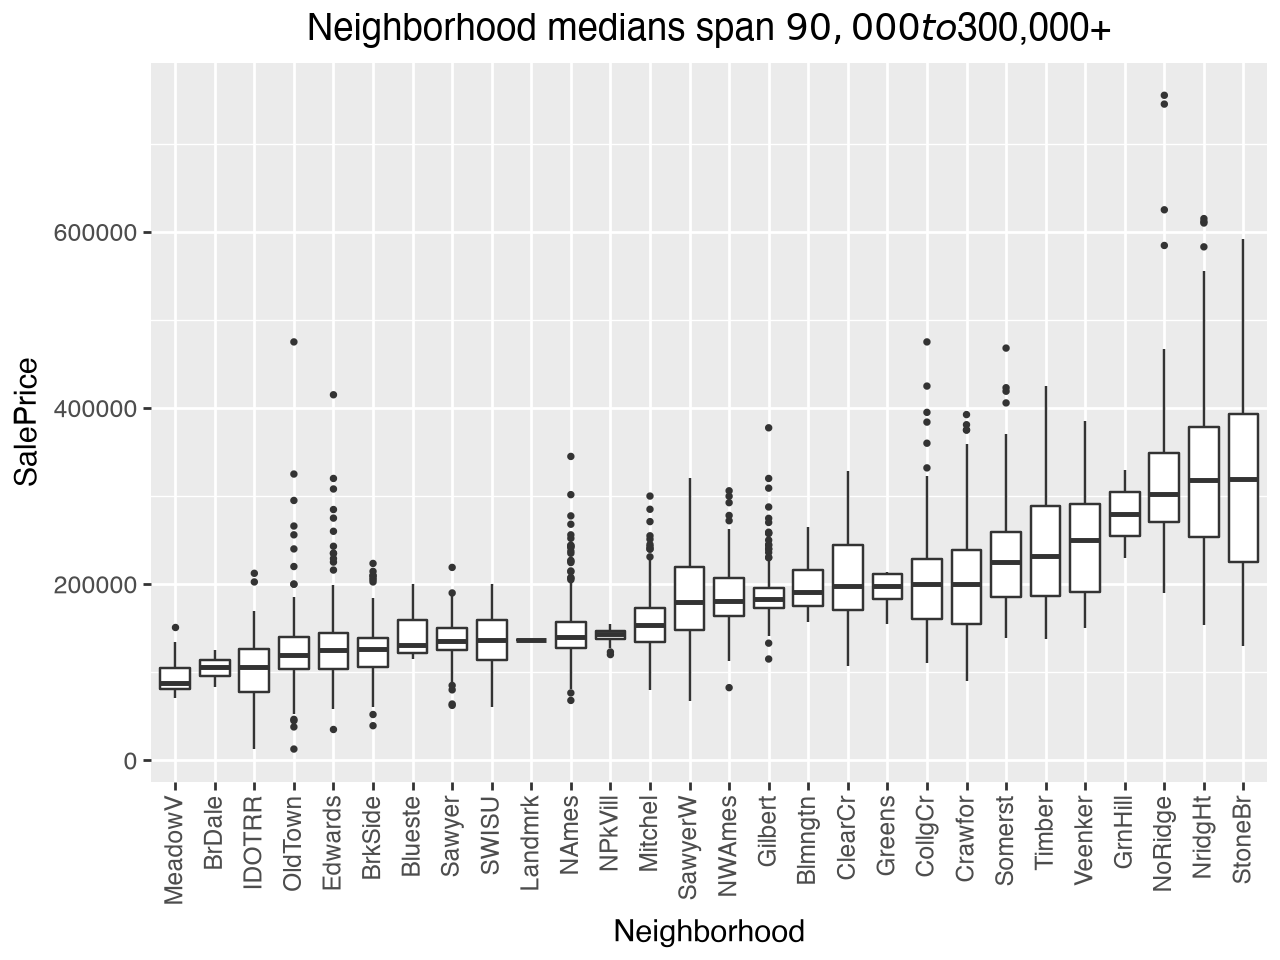

In [23]:
order = df_ames.groupby("Neighborhood")["SalePrice"].median().sort_values().index
(ggplot(df_ames, aes(x="Neighborhood", y="SalePrice"))
 + geom_boxplot(outlier_size=0.5)
 + scale_x_discrete(limits=list(order))
 + theme(axis_text_x=element_text(rotation=90))
 + labs(title="Neighborhood medians span $90,000 to $300,000+"))

In [24]:
df_ames.groupby("Kitchen Qual")["SalePrice"].agg(["median", "count"]).round(0)

,median,count
Kitchen Qual,,
Ex,325624.0,205
Fa,107750.0,70
Gd,201000.0,1160
Po,107500.0,1
TA,136500.0,1494


Three things stand out: **Overall Qual** is the single strongest numeric predictor (r ≈ 0.80, stronger than
living area); the price-vs-area cloud fans out, with the slope steepening for high-quality houses (an
**interaction** or a **square** will help a linear model); and the categorical columns **Neighborhood** and
**Kitchen Qual** / **Exter Qual** separate prices sharply. Also, `Overall Qual` and `Kitchen Qual` are quality
grades — the first is already a 1–10 number, the second is text and needs dummies.

**Linear models**, from the baseline up.

In [25]:
base4   = ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"]
twelve  = ["Gr Liv Area", "Overall Qual", "Year Built", "Year Remod/Add", "Total Bsmt SF", "Garage Cars",
           "Lot Area", "Fireplaces", "Bedroom AbvGr", "Full Bath", "Half Bath", "TotRms AbvGrd"]
cats4   = ["Neighborhood", "Kitchen Qual", "Exter Qual", "Bldg Type"]
cats6   = cats4 + ["Sale Condition", "Central Air"]

lm = LinearRegression
judge("linear: base 4 numeric",                       lm(), base4)
judge("linear: base 4 + Neighborhood",                Pipeline([("prep", preprocessing(base4, ["Neighborhood"])), ("model", lm())]), base4 + ["Neighborhood"])
judge("linear: 12 numeric",                           Pipeline([("prep", preprocessing(twelve)), ("model", lm())]), twelve)
judge("linear: 12 numeric + Neighborhood",            Pipeline([("prep", preprocessing(twelve, ["Neighborhood"])), ("model", lm())]), twelve + ["Neighborhood"])
judge("linear: 12 numeric + 4 categoricals",          Pipeline([("prep", preprocessing(twelve, cats4)), ("model", lm())]), twelve + cats4)
judge("linear: 12 numeric + 6 categoricals",          Pipeline([("prep", preprocessing(twelve, cats6)), ("model", lm())]), twelve + cats6);

linear: base 4 numeric                              51,354
linear: base 4 + Neighborhood                       39,567
linear: 12 numeric                                  35,285
linear: 12 numeric + Neighborhood                   32,601


linear: 12 numeric + 4 categoricals                 29,706


linear: 12 numeric + 6 categoricals                 29,629


**Polynomial features and an interaction.** `PolynomialFeatures(degree=2)` on the twelve numeric columns adds
every square and every pairwise product (90 columns), including the area × quality interaction the plot asked
for. Degree 3 is included on purpose: watch it collapse.

In [26]:
df_ames["Area x Qual"] = df_ames["Gr Liv Area"] * df_ames["Overall Qual"]

judge("linear: 12 numeric + Area x Qual + 4 categoricals", Pipeline([("prep", preprocessing(twelve + ["Area x Qual"], cats4)), ("model", lm())]), twelve + ["Area x Qual"] + cats4)
judge("linear: degree-2 poly (12 numeric) + 4 categoricals", Pipeline([("prep", preprocessing(twelve, cats4, degree=2)), ("model", lm())]), twelve + cats4)
judge("linear: degree-2 poly (12 numeric) + 6 categoricals", Pipeline([("prep", preprocessing(twelve, cats6, degree=2)), ("model", lm())]), twelve + cats6)
judge("linear: degree-3 poly (12 numeric) + 4 categoricals", Pipeline([("prep", preprocessing(twelve, cats4, degree=3)), ("model", lm())]), twelve + cats4);

linear: 12 numeric + Area x Qual + 4 categoricals    29,799


linear: degree-2 poly (12 numeric) + 4 categoricals    26,395


linear: degree-2 poly (12 numeric) + 6 categoricals    26,214


linear: degree-3 poly (12 numeric) + 4 categoricals    52,711


**K-nearest neighbors**, scaled numerics plus the neighborhood dummies, over a range of k.

In [27]:
for k in [3, 5, 8, 10, 15, 25]:
    judge(f"KNN: 12 numeric (scaled) + Neighborhood, k = {k}",
          Pipeline([("prep", preprocessing(twelve, ["Neighborhood"])), ("model", KNeighborsRegressor(n_neighbors=k))]),
          twelve + ["Neighborhood"])
judge("KNN: base 4 numeric (scaled), k = 10", Pipeline([("prep", preprocessing(base4)), ("model", KNeighborsRegressor(n_neighbors=10))]), base4);

KNN: 12 numeric (scaled) + Neighborhood, k = 3      28,920


KNN: 12 numeric (scaled) + Neighborhood, k = 5      28,851
KNN: 12 numeric (scaled) + Neighborhood, k = 8      28,899


KNN: 12 numeric (scaled) + Neighborhood, k = 10     29,327


KNN: 12 numeric (scaled) + Neighborhood, k = 15     29,541
KNN: 12 numeric (scaled) + Neighborhood, k = 25     30,290


KNN: base 4 numeric (scaled), k = 10                46,106


**Decision trees** over depth. No scaling (thresholds are on one feature at a time); `random_state` fixes the
tie-breaking so the numbers repeat.

In [28]:
for depth in [3, 5, 7, 9, 12, None]:
    judge(f"tree: 12 numeric + 4 categoricals, max_depth = {depth}",
          Pipeline([("prep", preprocessing(twelve, cats4, scale=False)),
                    ("model", DecisionTreeRegressor(max_depth=depth, random_state=5544))]),
          twelve + cats4)

tree: 12 numeric + 4 categoricals, max_depth = 3    41,990


tree: 12 numeric + 4 categoricals, max_depth = 5    36,280


tree: 12 numeric + 4 categoricals, max_depth = 7    35,209


tree: 12 numeric + 4 categoricals, max_depth = 9    32,579


tree: 12 numeric + 4 categoricals, max_depth = 12    35,302


tree: 12 numeric + 4 categoricals, max_depth = None    36,879


**The leaderboard.**

In [29]:
board = pd.Series(leaderboard, name="estimated test RMSE").sort_values().round(0).to_frame()
board["vs. baseline"] = (board["estimated test RMSE"] / board.loc["linear: base 4 numeric", "estimated test RMSE"]).round(2)
board

,estimated test RMSE,vs. baseline
linear: degree-2 poly (12 numeric) + 6 categoricals,26214.0,0.51
linear: degree-2 poly (12 numeric) + 4 categoricals,26395.0,0.51
"KNN: 12 numeric (scaled) + Neighborhood, k = 5",28851.0,0.56
"KNN: 12 numeric (scaled) + Neighborhood, k = 8",28899.0,0.56
"KNN: 12 numeric (scaled) + Neighborhood, k = 3",28920.0,0.56
"KNN: 12 numeric (scaled) + Neighborhood, k = 10",29327.0,0.57
"KNN: 12 numeric (scaled) + Neighborhood, k = 15",29541.0,0.58
linear: 12 numeric + 6 categoricals,29629.0,0.58
linear: 12 numeric + 4 categoricals,29706.0,0.58
linear: 12 numeric + Area x Qual + 4 categoricals,29799.0,0.58


In [30]:
best_name = board.index[0]
best_model = Pipeline([("prep", preprocessing(twelve, cats6, degree=2)), ("model", LinearRegression())])
best_scores = -cross_val_score(best_model, df_ames[twelve + cats6], y_train, cv=folds, scoring="neg_root_mean_squared_error")
print(best_name)
print("per-fold RMSE:", best_scores.round(0), "  mean:", round(best_scores.mean()), "  sd:", round(best_scores.std()))

linear: degree-2 poly (12 numeric) + 6 categoricals
per-fold RMSE: [24549. 33700. 20671. 28175. 19295. 25595. 26408. 29536. 28337. 25869.]   mean: 26214   sd: 3966


**What the code does.** `judge` cross-validates one candidate on the shared folds and stores the mean RMSE;
`preprocessing` builds the column transformer each pipeline needs; the loops are plain trial and error over
feature sets, k and depth; the leaderboard sorts the results.

**Expected output (same folds, `random_state=5544`).**

| family | best setting tried | estimated test RMSE |
|---|---|---|
| linear, 4 features (part 1) | — | ≈ 51,400 |
| linear, 4 features + Neighborhood | — | ≈ 39,600 |
| linear, 12 numeric + 6 categoricals | — | ≈ 29,600 |
| **linear, degree-2 polynomial on 12 numeric + 6 categoricals** | | **≈ 26,200** |
| linear, degree-3 polynomial | | ≈ 52,700 (!) |
| KNN, 12 numeric scaled + Neighborhood | k = 5 | ≈ 28,900 (k = 3 … 8 all within 100) |
| tree, 12 numeric + 4 categoricals | max_depth = 9 | ≈ 32,600 |

Reading it: **features mattered more than the model family.** Going from four columns to twelve took the
linear model from 51,400 to 35,300; the neighborhood and quality categoricals took it to 29,600; the squares and
products of the numeric columns (the steepening in the area plot) to about **26,200**, the winner and roughly a
third of the baseline's error. The degree-3 model has about 450 numeric columns and overfits spectacularly: a
textbook case of training error going down while test error explodes. KNN plateaus near 29,000 whatever k;
trees bottom out around depth 9 (32,600) and get worse both shallower and deeper, the U from Topic 9.2. The
winner's per-fold RMSEs run from about 20,000 to 34,000: the estimate is ±4,000 or so, so candidates within a
couple of thousand of each other are not really distinguishable on this evidence.

What students will typically find: adding `Overall Qual` is the single biggest win; adding `Neighborhood` the
second; polynomial terms help the linear model but only on the numeric columns (one-hot columns squared are
themselves); KNN needs scaling to be competitive at all (base-4 unscaled or wrong-scaled models sit near 47,000);
trees need depth 7–10.

**Common mistakes.**
- Comparing on **training** RMSE, which hands the win to the deepest tree or k = 1.
- Using **different folds** for different candidates (`cv=10` for one, a shuffled `KFold` for another): the
  comparison then mixes fold luck with model quality. One `folds` object, passed everywhere.
- **Scaling outside the pipeline**, or not at all for KNN.
- Leaving `handle_unknown="ignore"` off the encoder, then hitting `nan` scores or an error on a fold with a
  rare neighborhood (part 11).
- Columns with **missing values** (`Total Bsmt SF`, `Garage Cars`, `Garage Area`, `Mas Vnr Area`, many in
  `Lot Frontage`) crash `LinearRegression`; the imputer handles them, or choose complete columns.
- Applying `PolynomialFeatures` to the one-hot columns as well (hundreds of useless products), or going to
  degree 3 and reporting the lowest *training* RMSE ever seen.
- Modelling `log(SalePrice)` and reporting the RMSE in log units: the task fixes `SalePrice` in dollars.